In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df1 = pd.read_csv("ReLife_Cleaned_File1 (1).csv")
df2 = pd.read_csv("ReLife_Cleaned_File2.csv")

print("Dataset 1:", df1.shape)
print("Dataset 2:", df2.shape)

Dataset 1: (5000, 23)
Dataset 2: (70051, 17)


In [2]:
return_data = df1[df1["Return_Status"] == "Returned"]

category_returns = return_data["Product_Category"].value_counts()

print(category_returns)

Product_Category
Clothing           661
Electronics        314
Toys               181
Books              172
Home Appliances    122
Name: count, dtype: int64


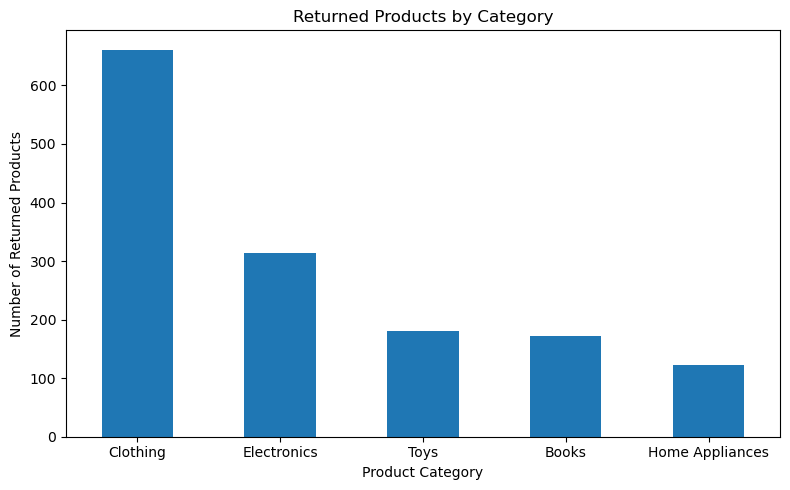

In [3]:
plt.figure(figsize=(8, 5))

category_returns.plot(kind="bar")

plt.title("Returned Products by Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Returned Products")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

Return_Status
Not Returned    3550
Returned        1450
Name: count, dtype: int64


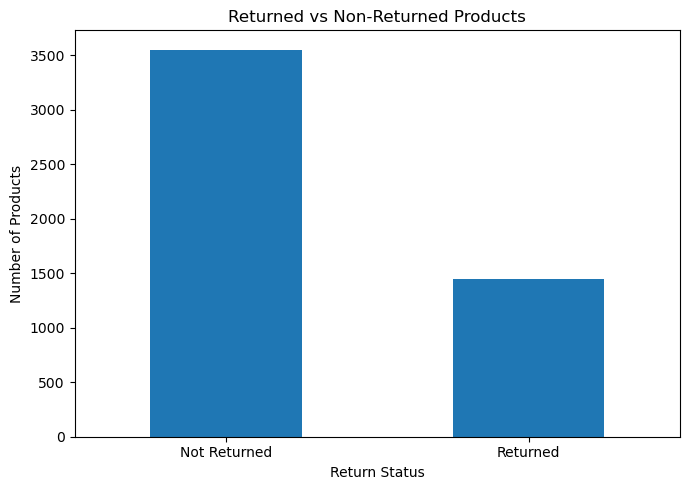

In [4]:

# Count returned and non-returned products

return_status = df1["Return_Status"].value_counts()

print(return_status)

# Create a bar chart
plt.figure(figsize=(7, 5))
return_status.plot(kind="bar")

plt.title("Returned vs Non-Returned Products")
plt.xlabel("Return Status")
plt.ylabel("Number of Products")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()


Return_Reason
Defective       382
Changed Mind    379
Wrong Item      348
Size Issue      341
Name: count, dtype: int64


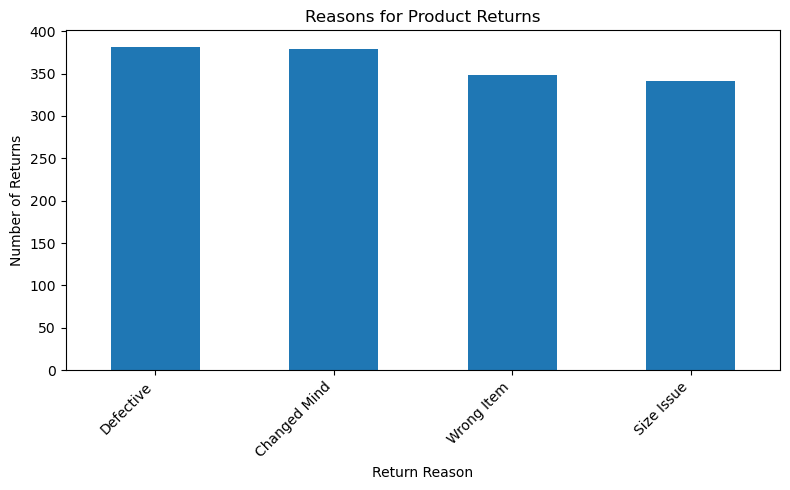

In [5]:

# Count the reasons for product returns

return_reasons = df1[df1["Return_Status"] == "Returned"]["Return_Reason"].value_counts()

print(return_reasons)

# Create a bar chart
plt.figure(figsize=(8, 5))
return_reasons.plot(kind="bar")

plt.title("Reasons for Product Returns")
plt.xlabel("Return Reason")
plt.ylabel("Number of Returns")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Product_Category
Clothing           37.43
Home Appliances    25.63
Electronics        25.24
Toys               24.07
Books              22.57
Name: count, dtype: float64


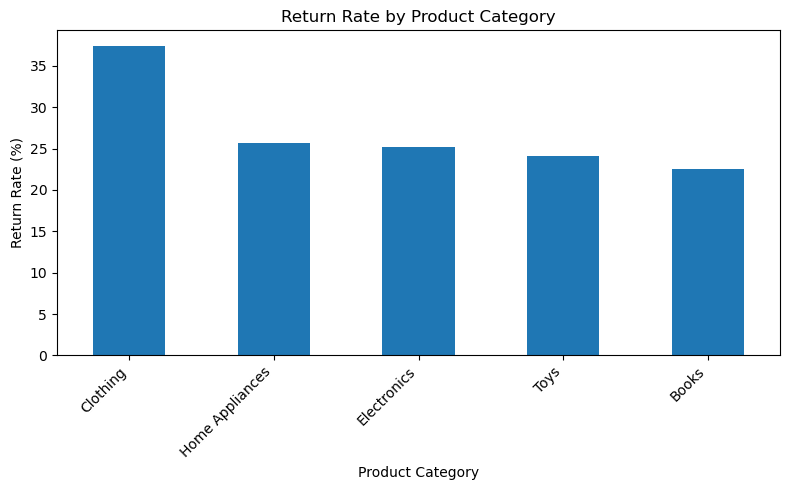

In [6]:

# Calculate the return rate for each product category

category_total = df1["Product_Category"].value_counts()

category_returned = df1[df1["Return_Status"] == "Returned"]["Product_Category"].value_counts()

return_rate = (category_returned / category_total * 100).sort_values(ascending=False)

print(return_rate.round(2))

# Create a bar chart
plt.figure(figsize=(8, 5))
return_rate.plot(kind="bar")

plt.title("Return Rate by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Return Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Return_Status     Not Returned  Returned
Product_Category                        
Books                      590       172
Clothing                  1105       661
Electronics                930       314
Home Appliances            354       122
Toys                       571       181


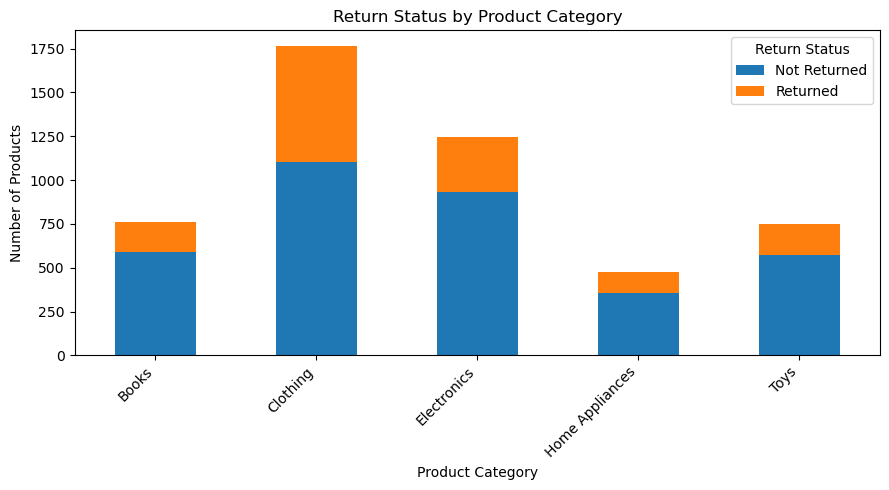

In [7]:

# Compare returned and non-returned products by category

status_by_category = pd.crosstab(
    df1["Product_Category"],
    df1["Return_Status"]
)

print(status_by_category)

# Create a stacked bar chart
status_by_category.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Return Status by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Return Status")
plt.tight_layout()

plt.show()


Month
2022-01    36
2022-02    32
2022-03    22
2022-04    34
2022-05    31
2022-06    29
2022-07    36
2022-08    28
2022-09    29
2022-10    28
2022-11    24
2022-12    33
2023-01    24
2023-02    26
2023-03    42
2023-04    36
2023-05    34
2023-06    26
2023-07    29
2023-08    32
2023-09    34
2023-10    41
2023-11    33
2023-12    34
2024-01    33
2024-02    43
2024-03    32
2024-04    31
2024-05    42
2024-06    29
2024-07    43
2024-08    35
2024-09    33
2024-10    36
2024-11    30
2024-12    42
2025-01    27
2025-02    36
2025-03    32
2025-04    36
2025-05    30
2025-06    29
2025-07    43
2025-08    33
2025-09     2
Name: count, dtype: int64


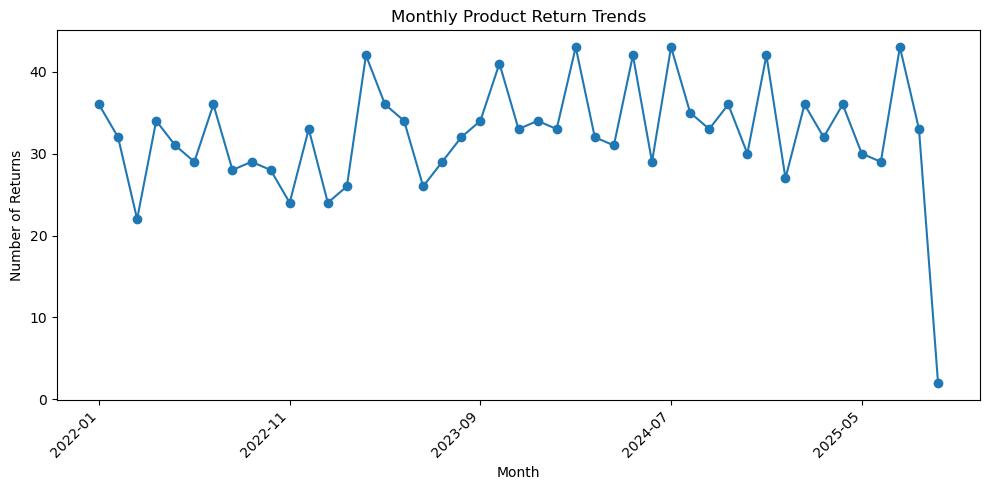

In [8]:

# Analyze monthly product returns

df1["Order_Date"] = pd.to_datetime(df1["Order_Date"])

returned_products = df1[df1["Return_Status"] == "Returned"].copy()

returned_products["Month"] = (
    returned_products["Order_Date"].dt.to_period("M").astype(str)
)

monthly_returns = returned_products["Month"].value_counts().sort_index()

print(monthly_returns)

# Create a line chart
plt.figure(figsize=(10, 5))
monthly_returns.plot(kind="line", marker="o")

plt.title("Monthly Product Return Trends")
plt.xlabel("Month")
plt.ylabel("Number of Returns")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


In [10]:

print(df1.columns.tolist())


['Order_ID', 'Product_ID', 'User_ID', 'Order_Date', 'Product_Category', 'Product_Price', 'Order_Quantity', 'Discount_Applied', 'Shipping_Method', 'Payment_Method', 'User_Age', 'User_Gender', 'User_Location', 'Return_Status', 'Return_Reason', 'Days_to_Return', 'Order_Value', 'Return_Cost', 'Profit_Loss', 'CO2_Emissions', 'Packaging_Waste', 'CO2_Saved', 'Waste_Avoided']


Product_ID
PROD0370    9
PROD0355    8
PROD0096    8
PROD0167    7
PROD0080    7
PROD0128    7
PROD0415    7
PROD0295    7
PROD0105    6
PROD0137    6
Name: count, dtype: int64


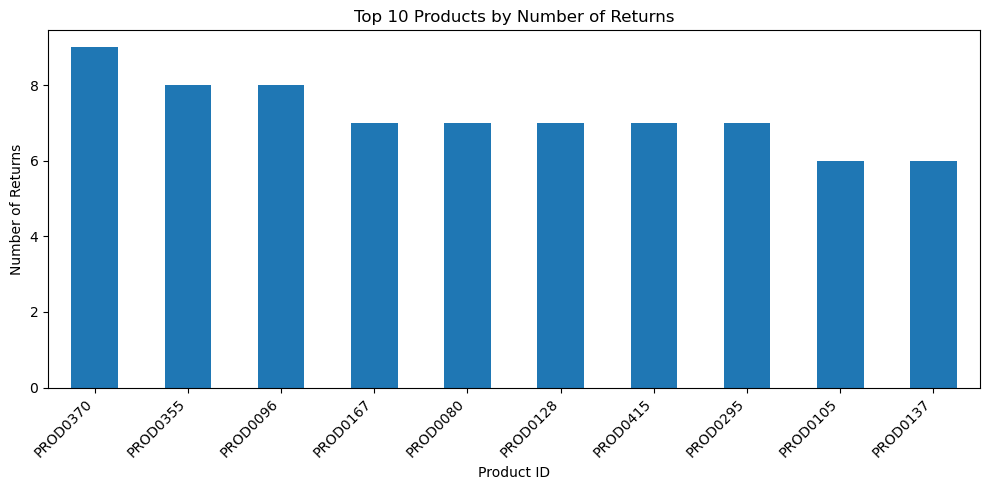

In [11]:

# Find the 10 most frequently returned products

top_returned_products = (
    df1[df1["Return_Status"] == "Returned"]["Product_ID"]
    .value_counts()
    .head(10)
)

print(top_returned_products)

# Create a bar chart
plt.figure(figsize=(10, 5))
top_returned_products.plot(kind="bar")

plt.title("Top 10 Products by Number of Returns")
plt.xlabel("Product ID")
plt.ylabel("Number of Returns")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Product_Category
Books              200.0
Clothing           200.0
Electronics        200.0
Home Appliances    200.0
Toys               200.0
Name: Return_Cost, dtype: float64


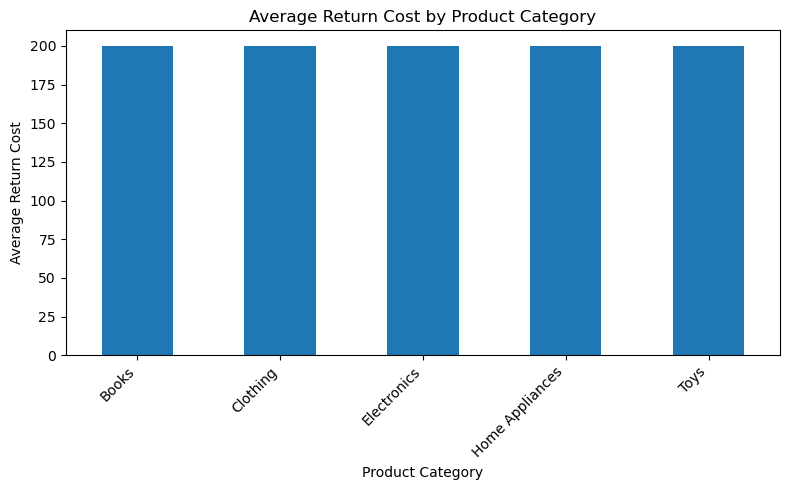

In [12]:

# Calculate average return cost for each product category

average_return_cost = (
    df1[df1["Return_Status"] == "Returned"]
    .groupby("Product_Category")["Return_Cost"]
    .mean()
    .sort_values(ascending=False)
)

print(average_return_cost.round(2))

# Create a bar chart
plt.figure(figsize=(8, 5))
average_return_cost.plot(kind="bar")

plt.title("Average Return Cost by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Return Cost")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Product_Category
Electronics        32.66
Clothing           32.52
Home Appliances    30.97
Toys               30.18
Books              29.24
Name: Days_to_Return, dtype: float64


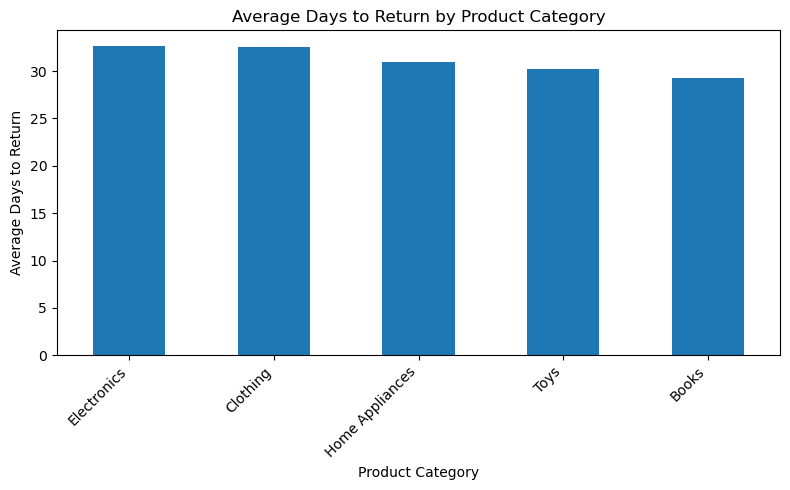

In [13]:

# Calculate average days taken to return products

average_days = (
    df1[df1["Return_Status"] == "Returned"]
    .groupby("Product_Category")["Days_to_Return"]
    .mean()
    .sort_values(ascending=False)
)

print(average_days.round(2))

# Create a bar chart
plt.figure(figsize=(8, 5))
average_days.plot(kind="bar")

plt.title("Average Days to Return by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Days to Return")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Product_Category
Toys               2418.49
Home Appliances    2368.04
Electronics        2287.33
Clothing           2286.42
Books              2251.75
Name: Profit_Loss, dtype: float64


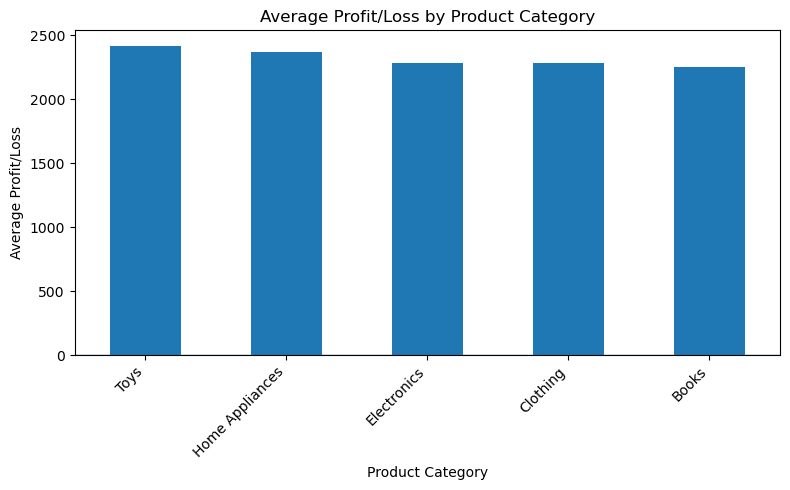

In [14]:

# Calculate average profit or loss by product category

average_profit_loss = (
    df1.groupby("Product_Category")["Profit_Loss"]
    .mean()
    .sort_values(ascending=False)
)

print(average_profit_loss.round(2))

# Create a bar chart
plt.figure(figsize=(8, 5))
average_profit_loss.plot(kind="bar")

plt.title("Average Profit/Loss by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Profit/Loss")
plt.axhline(y=0, linewidth=1)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Product_Category
Clothing           2631.5
Electronics        1858.0
Books              1159.5
Toys               1130.0
Home Appliances     721.5
Name: CO2_Emissions, dtype: float64


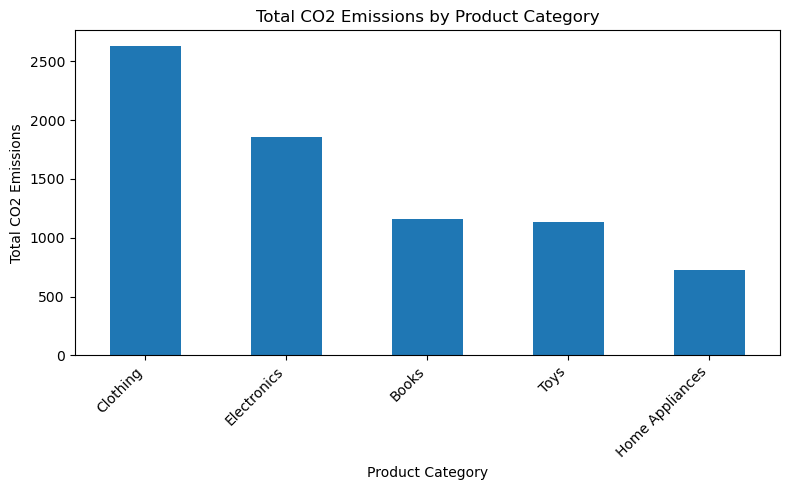

In [15]:

# Calculate total CO2 emissions by product category

co2_by_category = (
    df1.groupby("Product_Category")["CO2_Emissions"]
    .sum()
    .sort_values(ascending=False)
)

print(co2_by_category.round(2))

# Create a bar chart
plt.figure(figsize=(8, 5))
co2_by_category.plot(kind="bar")

plt.title("Total CO2 Emissions by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total CO2 Emissions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Product_Category
Clothing           1640.0
Electronics        1381.0
Books               907.5
Toys                865.0
Home Appliances     539.5
Name: CO2_Saved, dtype: float64


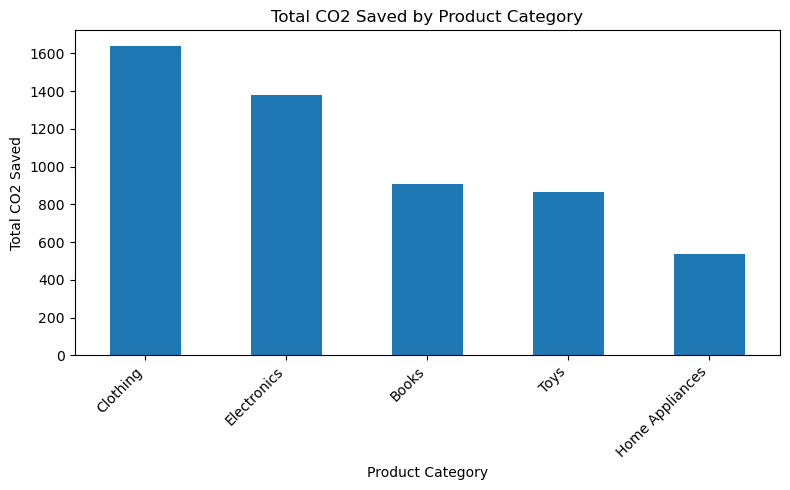

In [16]:

# Calculate total CO2 saved by product category

co2_saved_by_category = (
    df1.groupby("Product_Category")["CO2_Saved"]
    .sum()
    .sort_values(ascending=False)
)

print(co2_saved_by_category.round(2))

# Create a bar chart
plt.figure(figsize=(8, 5))
co2_saved_by_category.plot(kind="bar")

plt.title("Total CO2 Saved by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total CO2 Saved")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Product_Category
Clothing           1043.8
Electronics         753.6
Toys                461.2
Books               449.4
Home Appliances     289.6
Name: Packaging_Waste, dtype: float64


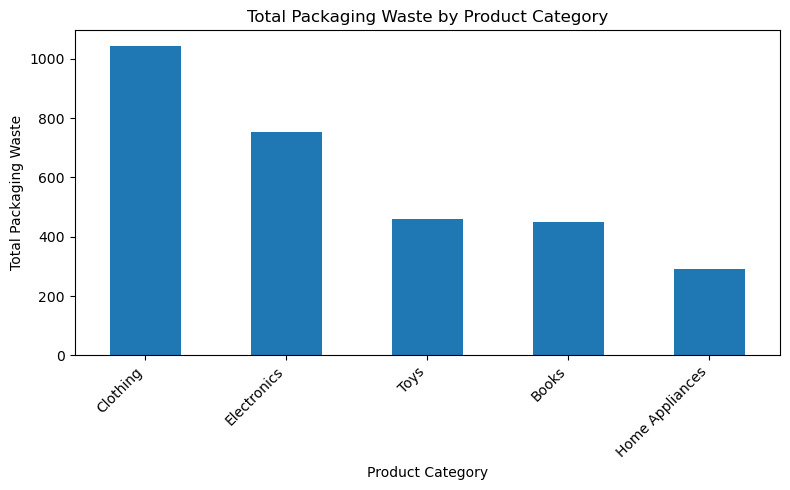

In [17]:

# Calculate total packaging waste by product category

waste_by_category = (
    df1.groupby("Product_Category")["Packaging_Waste"]
    .sum()
    .sort_values(ascending=False)
)

print(waste_by_category.round(2))

# Create a bar chart
plt.figure(figsize=(8, 5))
waste_by_category.plot(kind="bar")

plt.title("Total Packaging Waste by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Packaging Waste")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Product_Category
Clothing           656.8
Electronics        566.0
Toys               348.8
Books              346.4
Home Appliances    215.4
Name: Waste_Avoided, dtype: float64


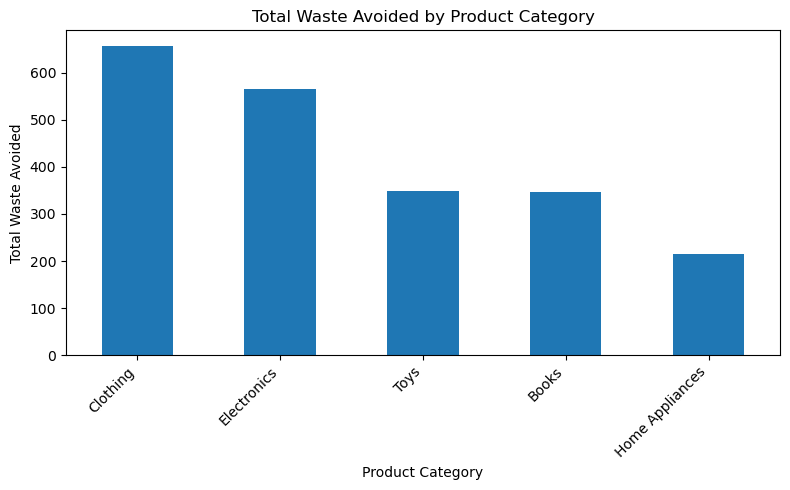

In [18]:

# Calculate total waste avoided by product category

waste_avoided_by_category = (
    df1.groupby("Product_Category")["Waste_Avoided"]
    .sum()
    .sort_values(ascending=False)
)

print(waste_avoided_by_category.round(2))

# Create a bar chart
plt.figure(figsize=(8, 5))
waste_avoided_by_category.plot(kind="bar")

plt.title("Total Waste Avoided by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Waste Avoided")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Category
Product P    1511738.79
Product H     969373.66
Product D     412466.87
Product B     234302.92
Product A     227563.78
Product W     165534.37
Product C     154883.93
Product J     128959.24
Product N     113932.90
Product F      90083.86
Product O      66020.51
Product R      54820.87
Product I      39709.78
Product G      31130.02
Product M      28414.93
DPR            28063.00
Product Q      26293.02
Product E      18147.97
Product U      11389.97
Product T       7035.66
Product L       6974.95
Product K        633.33
Product S          0.00
Name: Total Revenue, dtype: float64


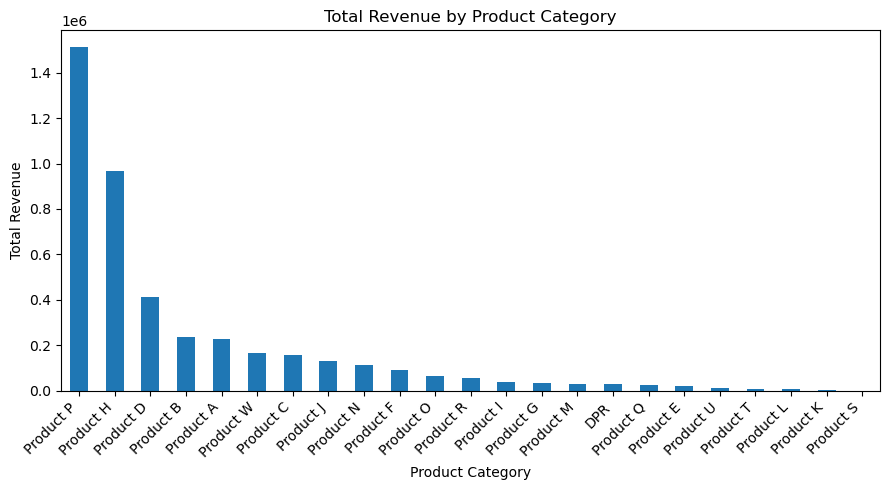

In [19]:

# Calculate total revenue by product category

revenue_by_category = (
    df2.groupby("Category")["Total Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(revenue_by_category.round(2))

# Create a bar chart
plt.figure(figsize=(9, 5))
revenue_by_category.plot(kind="bar")

plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Category
Product P    1123733.63
Product H     708320.69
Product D     302613.41
Product B     176144.31
Product A     173388.87
Product C     119540.33
Product W     118294.52
Product J     100388.44
Product N      86675.01
Product F      70515.86
Product O      63143.32
Product R      43557.58
Product I      37726.09
Product G      29717.30
DPR            27018.00
Product M      25683.52
Product Q      21214.02
Product E      15578.95
Product U       7901.41
Product L       6374.13
Product T       5115.45
Product K        425.84
Product S        -82.50
Name: Final Revenue, dtype: float64


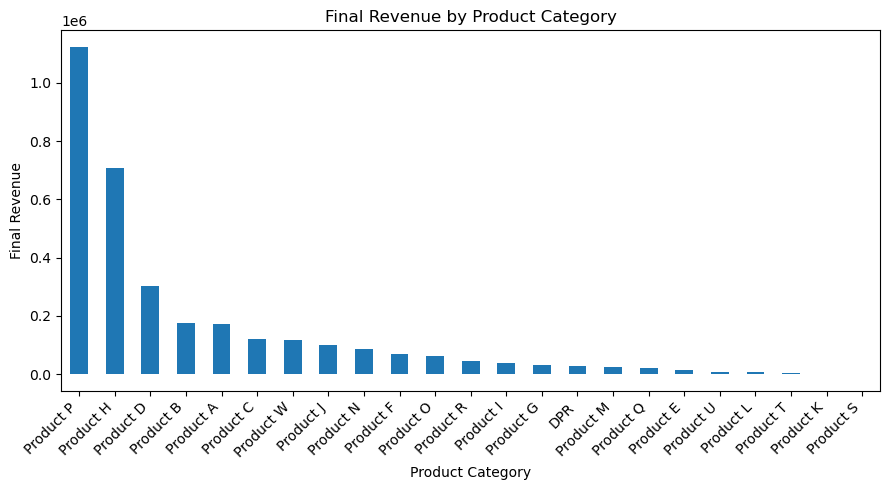

In [20]:

# Calculate final revenue by product category

final_revenue_by_category = (
    df2.groupby("Category")["Final Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(final_revenue_by_category.round(2))

# Create a bar chart
plt.figure(figsize=(9, 5))
final_revenue_by_category.plot(kind="bar")

plt.title("Final Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Final Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Category
Product S       -82.50
Product K      -158.34
Product I      -229.86
DPR            -427.20
Product L      -431.25
Product G      -508.40
Product O     -1198.88
Product T     -1620.86
Product M     -1853.63
Product E     -1957.57
Product U     -2960.96
Product Q     -4474.58
Product R     -9301.28
Product F    -14166.97
Product N    -21436.70
Product C    -24067.32
Product J    -27146.99
Product W    -31398.54
Product A    -34482.58
Product B    -38617.16
Product D    -78645.10
Product H   -169003.29
Product P   -253586.37
Name: Refunds, dtype: float64


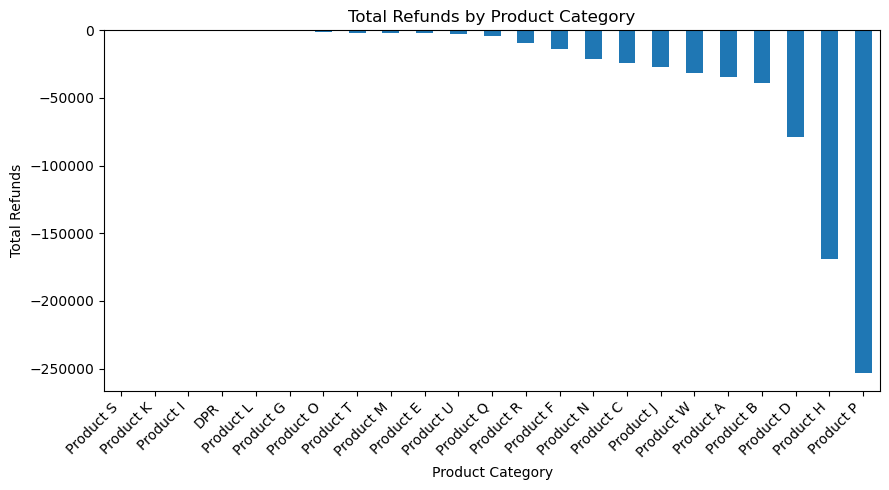

In [21]:

# Calculate total refunds by product category

refunds_by_category = (
    df2.groupby("Category")["Refunds"]
    .sum()
    .sort_values(ascending=False)
)

print(refunds_by_category.round(2))

# Create a bar chart
plt.figure(figsize=(9, 5))
refunds_by_category.plot(kind="bar")

plt.title("Total Refunds by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Refunds")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Category
Product P    16204
Product H    10898
Product D     4728
Product B     2472
Product N     2306
Product W     1771
Product A     1766
Product C     1760
Product R     1546
Product O     1125
Product J     1021
Product F      749
Product G      532
Product I      497
Product Q      452
Product M      373
DPR            280
Product U      229
Product E      162
Product T      138
Product L      104
Product K        6
Product S       -1
Name: Final Quantity, dtype: int64


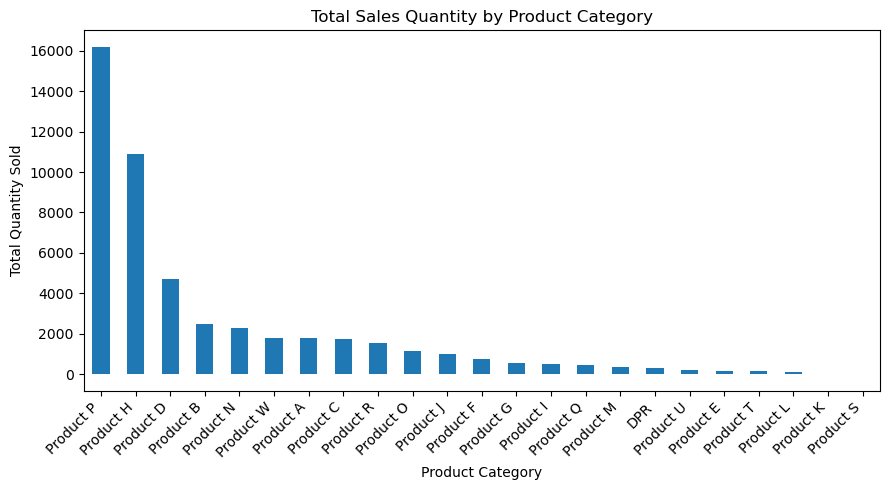

In [22]:

# Calculate total quantity sold by product category

quantity_by_category = (
    df2.groupby("Category")["Final Quantity"]
    .sum()
    .sort_values(ascending=False)
)

print(quantity_by_category)

# Create a bar chart
plt.figure(figsize=(9, 5))
quantity_by_category.plot(kind="bar")

plt.title("Total Sales Quantity by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Category
Product S         0.00
Product K       -49.15
Product L      -169.57
Product T      -299.35
Product U      -527.60
Product Q      -604.42
Product E      -611.45
DPR            -617.80
Product M      -877.78
Product G      -904.32
Product J     -1423.81
Product O     -1678.31
Product I     -1753.83
Product R     -1962.01
Product F     -5401.03
Product N     -5821.19
Product C    -11276.28
Product W    -15841.31
Product B    -19541.45
Product A    -19692.33
Product D    -31208.36
Product H    -92049.68
Product P   -134418.79
Name: Price Reductions, dtype: float64


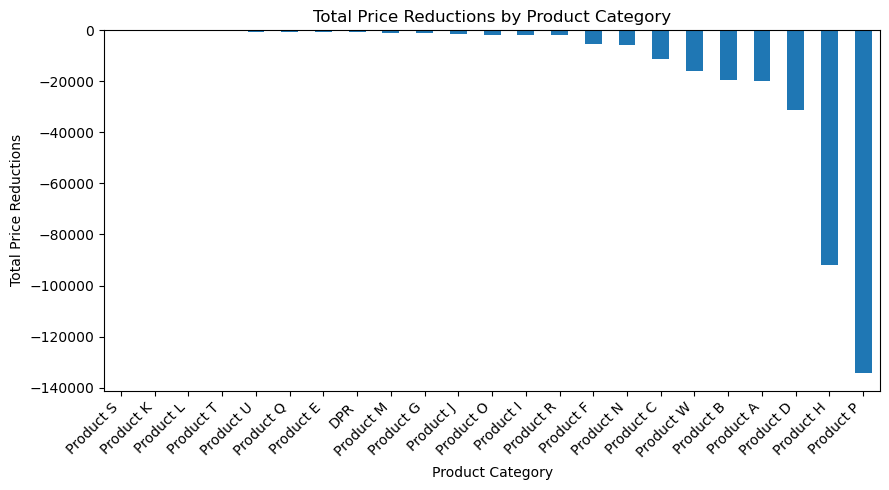

In [23]:

# Calculate total price reductions by product category

reductions_by_category = (
    df2.groupby("Category")["Price Reductions"]
    .sum()
    .sort_values(ascending=False)
)

print(reductions_by_category.round(2))

# Create a bar chart
plt.figure(figsize=(9, 5))
reductions_by_category.plot(kind="bar")

plt.title("Total Price Reductions by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Price Reductions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Category
DPR          105.50
Product A     92.47
Product E     90.29
Product F     85.39
Product J     83.25
Product I     79.58
Product B     66.75
Product P     64.74
Product K     63.33
Product M     63.28
Product C     63.06
Product W     61.84
Product H     60.73
Product L     60.65
Product D     58.27
Product O     57.01
Product G     56.81
Product Q     41.21
Product N     34.03
Product T     30.86
Product U     29.74
Product R     26.03
Product S      0.00
Name: Total Revenue, dtype: float64


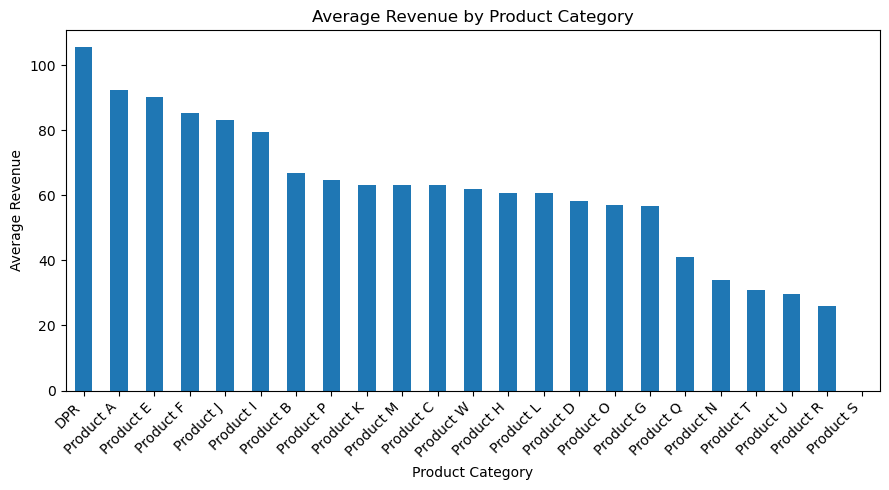

In [24]:

# Calculate average revenue by product category

average_revenue = (
    df2.groupby("Category")["Total Revenue"]
    .mean()
    .sort_values(ascending=False)
)

print(average_revenue.round(2))

# Create a bar chart
plt.figure(figsize=(9, 5))
average_revenue.plot(kind="bar")

plt.title("Average Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Date
2018-11   -131820.32
2018-12   -122448.96
2019-01   -179656.12
2019-02    -79313.10
2019-03   -101876.94
2019-04   -102640.89
Freq: M, Name: Refunds, dtype: float64


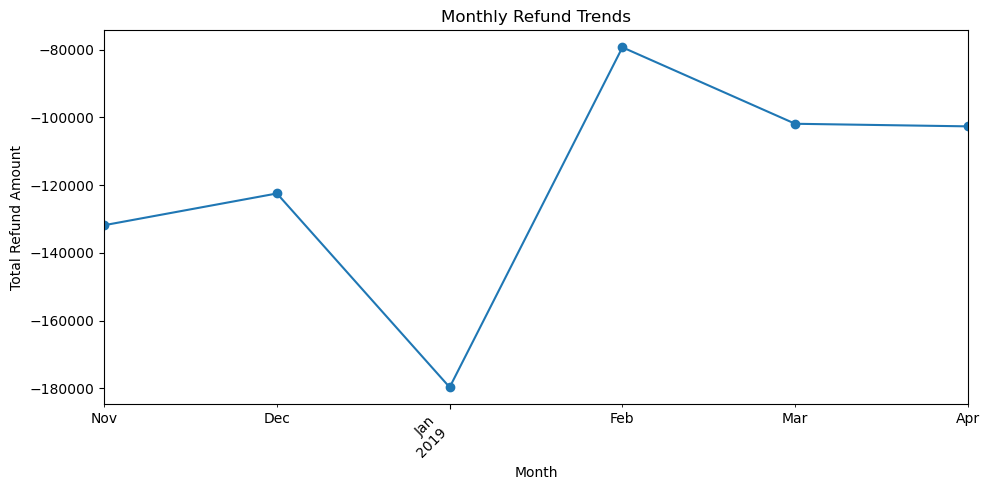

In [25]:

# Calculate monthly refund amounts

df2["Date"] = pd.to_datetime(df2["Date"])

monthly_refunds = (
    df2.groupby(df2["Date"].dt.to_period("M"))["Refunds"]
    .sum()
)

print(monthly_refunds.round(2))

# Create a line chart
plt.figure(figsize=(10, 5))
monthly_refunds.plot(kind="line", marker="o")

plt.title("Monthly Refund Trends")
plt.xlabel("Month")
plt.ylabel("Total Refund Amount")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Purchased Items    60053
Refunded Items    -10935
dtype: int64


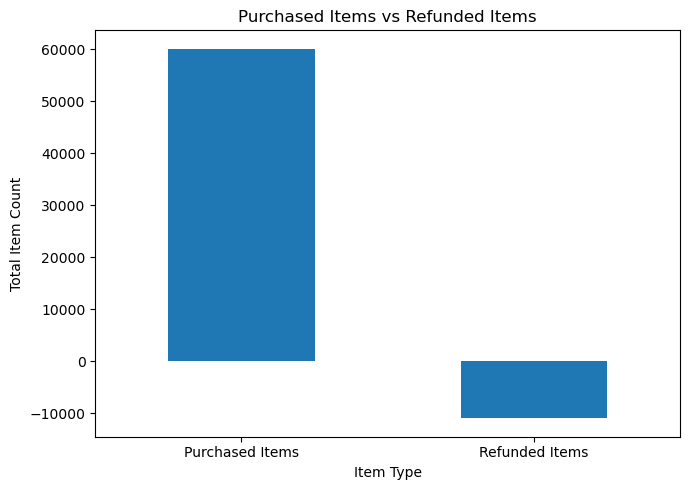

In [26]:

# Compare purchased and refunded item counts

item_counts = pd.Series({
    "Purchased Items": df2["Purchased Item Count"].sum(),
    "Refunded Items": df2["Refunded Item Count"].sum()
})

print(item_counts)

# Create a bar chart
plt.figure(figsize=(7, 5))
item_counts.plot(kind="bar")

plt.title("Purchased Items vs Refunded Items")
plt.xlabel("Item Type")
plt.ylabel("Total Item Count")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()


Category
Product P    1345800.72
Product H     848232.33
Product D     362369.22
Product B     211079.13
Product A     207539.70
Product C     143176.21
Product W     141666.27
Product J     120110.14
Product N     103739.01
Product F      84373.56
Product O      75626.82
Product R      52179.87
Product I      45120.72
Product G      35633.33
Product M      30761.19
DPR            27018.00
Product Q      25400.22
Product E      18694.44
Product U       9454.53
Product L       7603.94
Product T       6114.03
Product K        511.00
Product S        -99.00
Name: Overall Revenue, dtype: float64


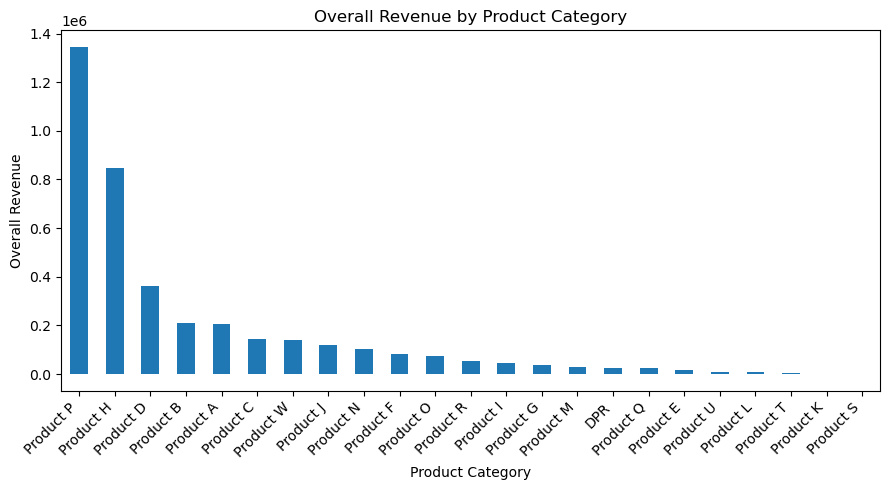

In [27]:

# Calculate overall revenue by product category

overall_revenue_by_category = (
    df2.groupby("Category")["Overall Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(overall_revenue_by_category.round(2))

# Create a bar chart
plt.figure(figsize=(9, 5))
overall_revenue_by_category.plot(kind="bar")

plt.title("Overall Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Overall Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Category
Product P    222067.13
Product H    139911.67
Product D     59755.81
Product B     34934.83
Product A     34150.83
Product C     23635.88
Product W     23371.75
Product J     19721.70
Product N     17064.01
Product F     13857.70
Product O     12483.50
Product R      8622.31
Product I      7394.63
Product G      5916.03
Product M      5077.67
Product Q      4186.20
Product E      3115.49
Product U      1553.12
Product L      1229.81
Product T       998.58
Product K        85.16
DPR               0.00
Product S       -16.50
Name: Sales Tax, dtype: float64


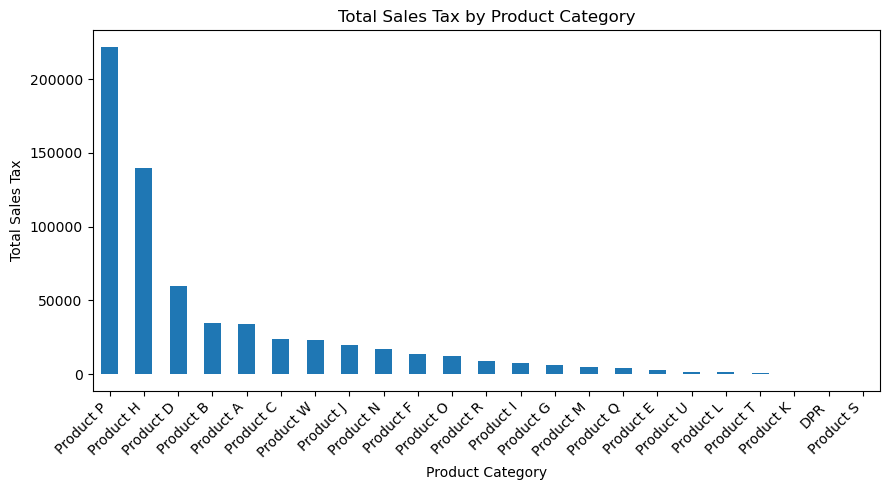

In [28]:

# Calculate total sales tax by product category

tax_by_category = (
    df2.groupby("Category")["Sales Tax"]
    .sum()
    .sort_values(ascending=False)
)

print(tax_by_category.round(2))

# Create a bar chart
plt.figure(figsize=(9, 5))
tax_by_category.plot(kind="bar")

plt.title("Total Sales Tax by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales Tax")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


In [30]:

print(df2.columns.tolist())


['Item Name', 'Category', 'Version', 'Item Code', 'Item ID', 'Buyer ID', 'Transaction ID', 'Date', 'Final Quantity', 'Total Revenue', 'Price Reductions', 'Refunds', 'Final Revenue', 'Sales Tax', 'Overall Revenue', 'Refunded Item Count', 'Purchased Item Count']


Category
DPR          105.50
Product A     92.47
Product E     90.29
Product F     85.39
Product J     83.25
Product I     79.58
Product B     66.75
Product P     64.74
Product K     63.33
Product M     63.28
Product C     63.06
Product W     61.84
Product H     60.73
Product L     60.65
Product D     58.27
Product O     57.01
Product G     56.81
Product Q     41.21
Product N     34.03
Product T     30.86
Product U     29.74
Product R     26.03
Product S      0.00
Name: Total Revenue, dtype: float64


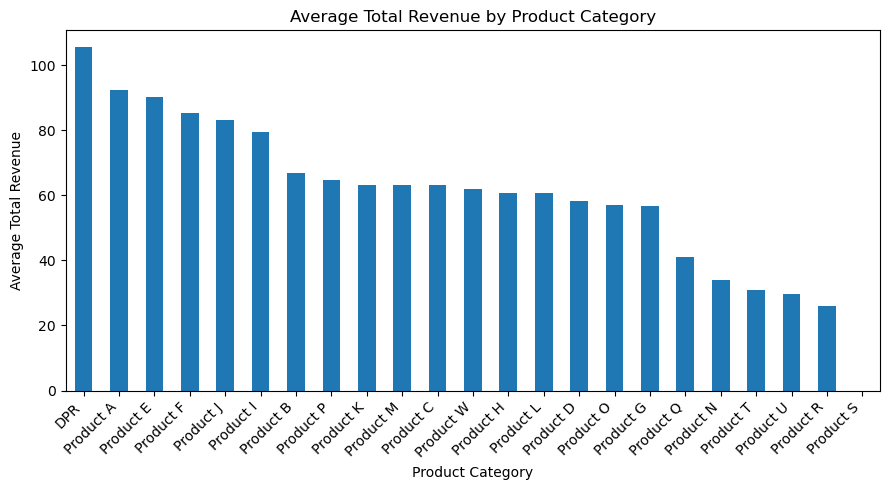

In [31]:

# Calculate average total revenue by product category

average_revenue_by_category = (
    df2.groupby("Category")["Total Revenue"]
    .mean()
    .sort_values(ascending=False)
)

print(average_revenue_by_category.round(2))

# Create a bar chart
plt.figure(figsize=(9, 5))
average_revenue_by_category.plot(kind="bar")

plt.title("Average Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Total Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Item Name
WHX    872942.23
YQX    438632.56
RJF    303890.20
XEB    242763.09
QID    236122.29
KNB    219071.19
NMA    207464.85
AYN    194873.11
LQS    178741.21
OTH    149371.80
Name: Total Revenue, dtype: float64


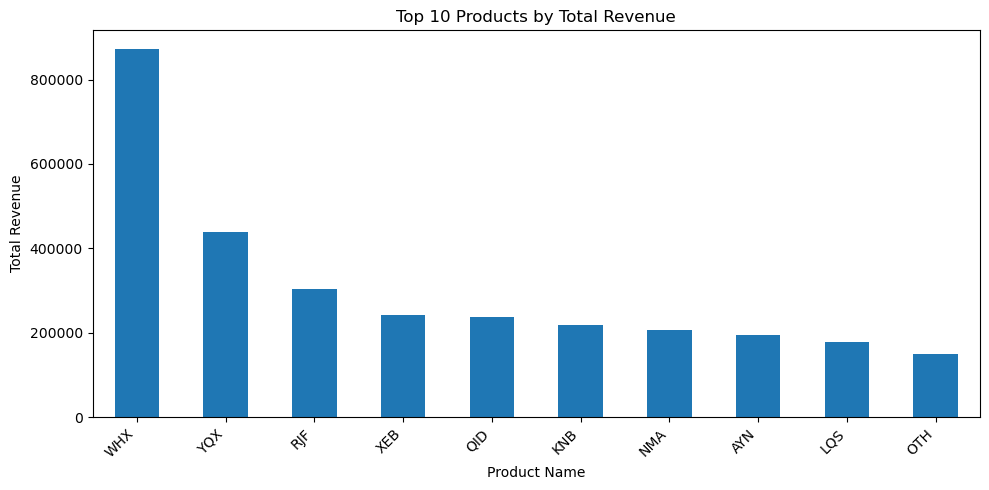

In [32]:

# Find the top 10 products by total revenue

top_products_revenue = (
    df2.groupby("Item Name")["Total Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products_revenue.round(2))

# Create a bar chart
plt.figure(figsize=(10, 5))
top_products_revenue.plot(kind="bar")

plt.title("Top 10 Products by Total Revenue")
plt.xlabel("Product Name")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Date
2018-11    1120833.76
2018-12     716224.56
2019-01     603449.37
2019-02     480994.73
2019-03     636511.48
2019-04     769460.43
Freq: M, Name: Total Revenue, dtype: float64


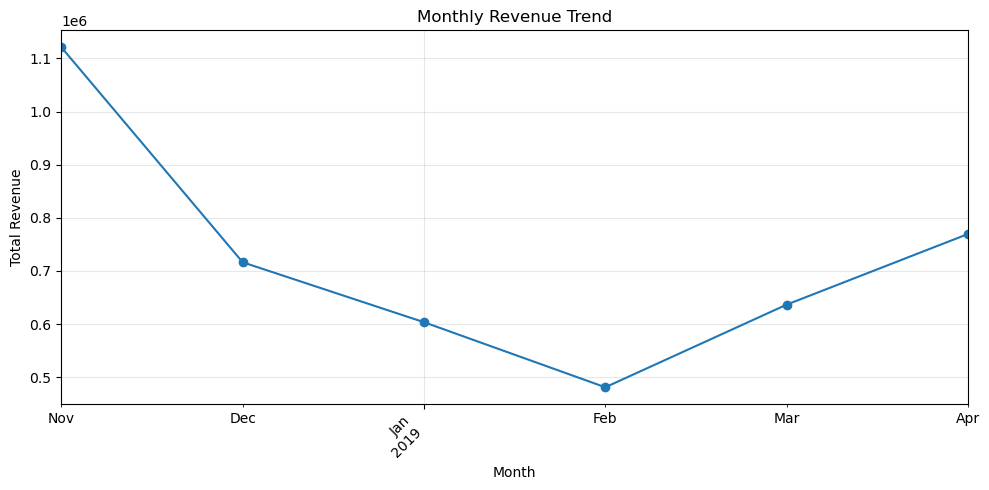

In [33]:

# Calculate monthly revenue

df2["Date"] = pd.to_datetime(df2["Date"])

monthly_revenue = (
    df2.groupby(df2["Date"].dt.to_period("M"))["Total Revenue"]
    .sum()
)

print(monthly_revenue.round(2))

# Create a line chart
plt.figure(figsize=(10, 5))
monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Category
DPR           0.65
Product A     5.26
Product B     5.41
Product C     3.58
Product D     9.53
Product E     0.42
Product F     2.08
Product G     0.72
Product H    22.40
Product I     0.92
Product J     2.98
Product K     0.01
Product L     0.16
Product M     0.66
Product N     2.63
Product O     1.53
Product P    34.93
Product Q     0.61
Product R     1.27
Product S     0.00
Product T     0.16
Product U     0.26
Product W     3.83
Name: Total Revenue, dtype: float64


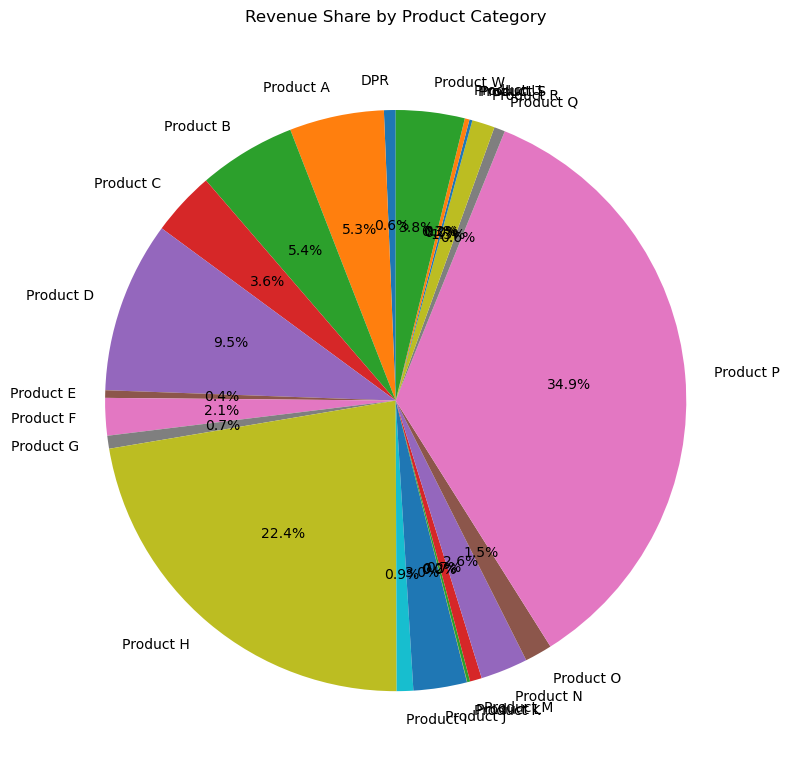

In [34]:

# Calculate revenue share by category

revenue_share = df2.groupby("Category")["Total Revenue"].sum()

print((revenue_share / revenue_share.sum() * 100).round(2))

# Create a pie chart
plt.figure(figsize=(8, 8))

plt.pie(
    revenue_share,
    labels=revenue_share.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Share by Product Category")
plt.axis("equal")
plt.tight_layout()

plt.show()


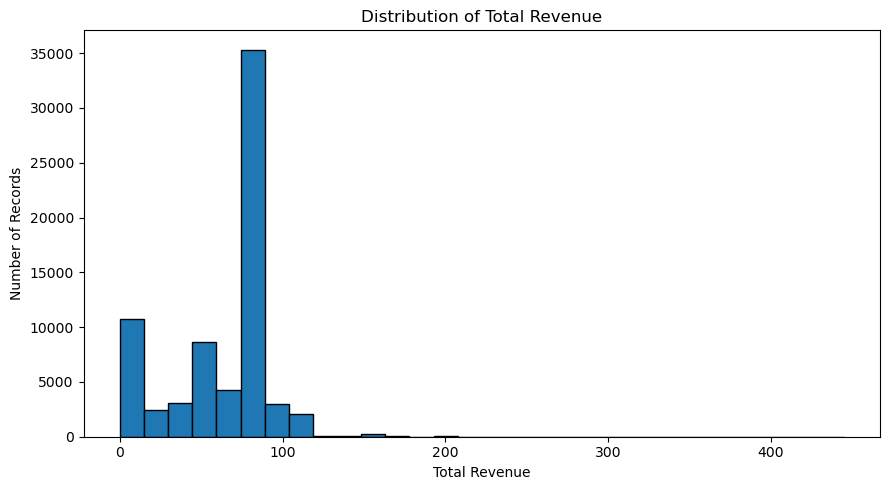

In [35]:

# Visualize the distribution of total revenue

plt.figure(figsize=(9, 5))

plt.hist(df2["Total Revenue"].dropna(), bins=30, edgecolor="black")

plt.title("Distribution of Total Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Number of Records")
plt.tight_layout()

plt.show()


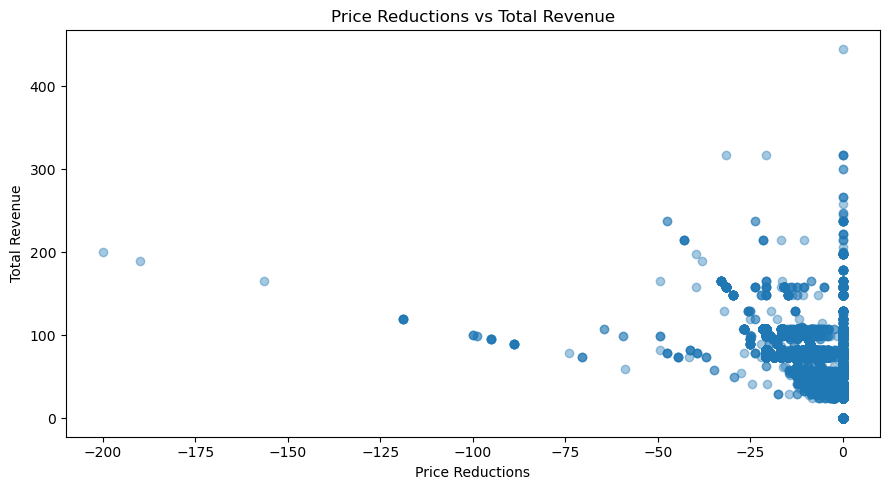

In [36]:

# Explore the relationship between price reductions and total revenue

plt.figure(figsize=(9, 5))

plt.scatter(
    df2["Price Reductions"],
    df2["Total Revenue"],
    alpha=0.4
)

plt.title("Price Reductions vs Total Revenue")
plt.xlabel("Price Reductions")
plt.ylabel("Total Revenue")
plt.tight_layout()

plt.show()


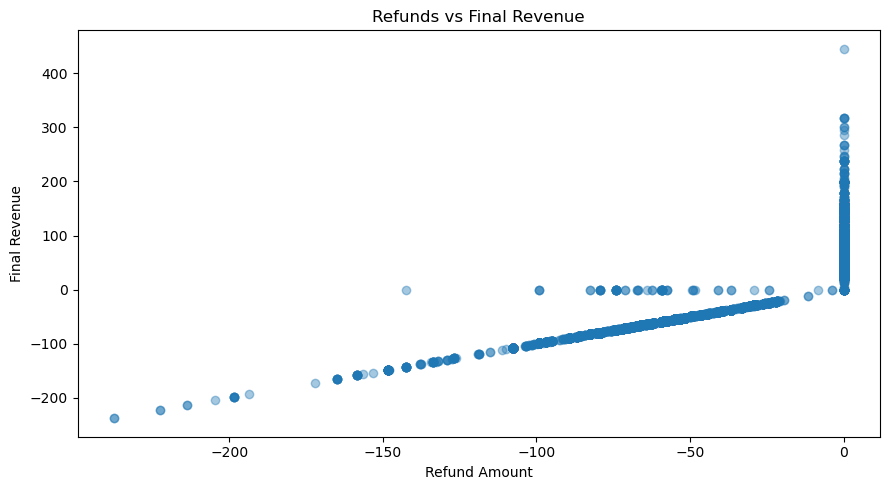

In [37]:

# Explore the relationship between refunds and final revenue

plt.figure(figsize=(9, 5))

plt.scatter(
    df2["Refunds"],
    df2["Final Revenue"],
    alpha=0.4
)

plt.title("Refunds vs Final Revenue")
plt.xlabel("Refund Amount")
plt.ylabel("Final Revenue")
plt.tight_layout()

plt.show()


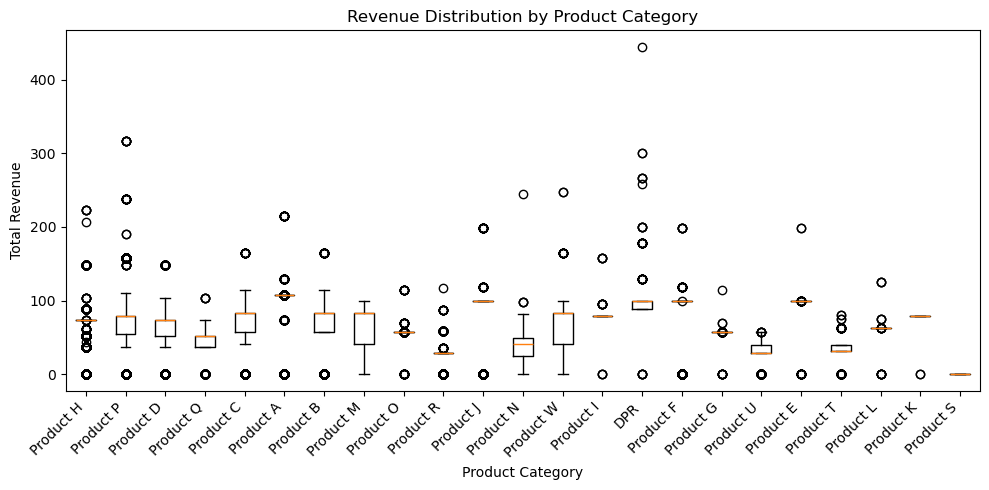

In [38]:

# Compare revenue distributions across product categories

categories = df2["Category"].dropna().unique()

revenue_data = [
    df2.loc[df2["Category"] == category, "Total Revenue"].dropna()
    for category in categories
]

plt.figure(figsize=(10, 5))

plt.boxplot(revenue_data, tick_labels=categories)

plt.title("Revenue Distribution by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Date
2018-11    12170
2018-12     8218
2019-01     6631
2019-02     4776
2019-03     7984
2019-04     9339
Freq: M, Name: Final Quantity, dtype: int64


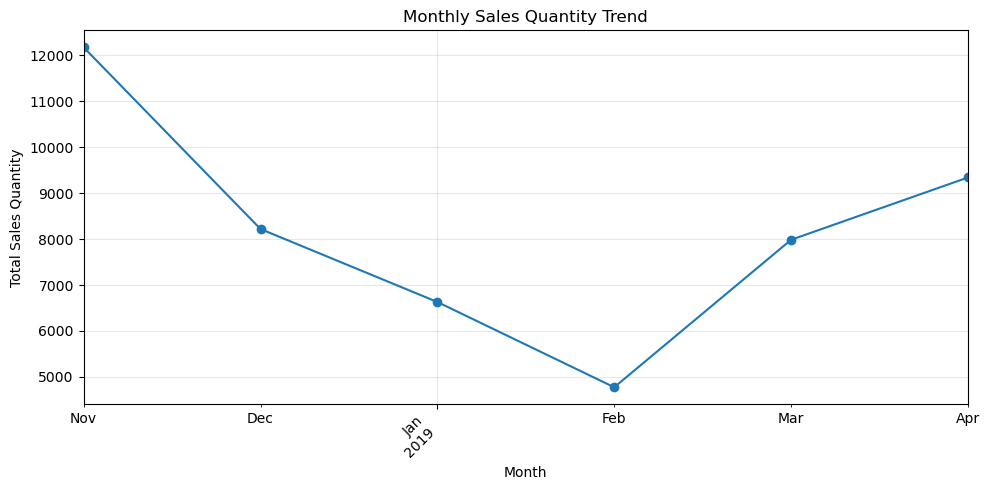

In [39]:

# Calculate monthly sales quantity

monthly_quantity = (
    df2.groupby(df2["Date"].dt.to_period("M"))["Final Quantity"]
    .sum()
    .sort_index()
)

print(monthly_quantity)

# Create a line chart
plt.figure(figsize=(10, 5))

monthly_quantity.plot(kind="line", marker="o")

plt.title("Monthly Sales Quantity Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales Quantity")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


           Total Revenue    Refunds
Category                           
DPR             28063.00    -427.20
Product A      227563.78  -34482.58
Product B      234302.92  -38617.16
Product C      154883.93  -24067.32
Product D      412466.87  -78645.10
Product E       18147.97   -1957.57
Product F       90083.86  -14166.97
Product G       31130.02    -508.40
Product H      969373.66 -169003.29
Product I       39709.78    -229.86
Product J      128959.24  -27146.99
Product K         633.33    -158.34
Product L        6974.95    -431.25
Product M       28414.93   -1853.63
Product N      113932.90  -21436.70
Product O       66020.51   -1198.88
Product P     1511738.79 -253586.37
Product Q       26293.02   -4474.58
Product R       54820.87   -9301.28
Product S           0.00     -82.50
Product T        7035.66   -1620.86
Product U       11389.97   -2960.96
Product W      165534.37  -31398.54


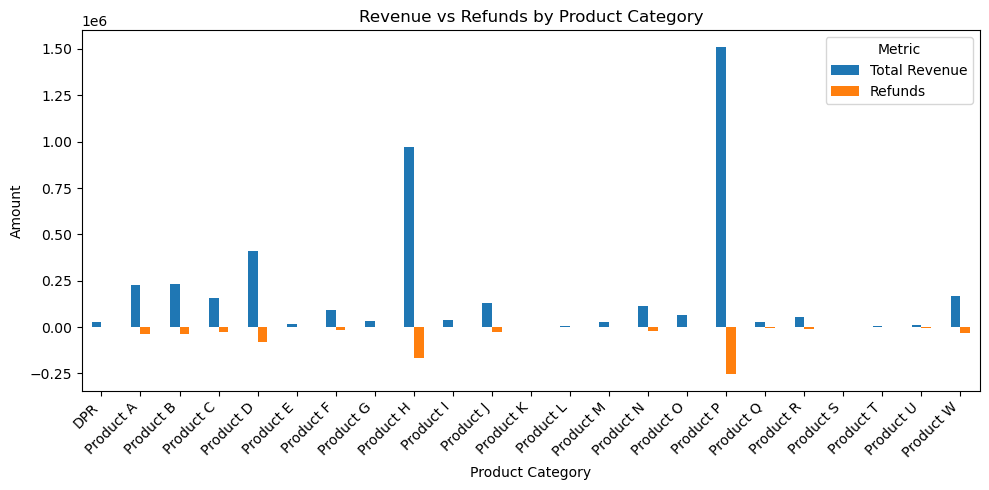

In [40]:

# Compare total revenue and refunds by category

category_comparison = df2.groupby("Category")[
    ["Total Revenue", "Refunds"]
].sum()

print(category_comparison.round(2))

# Create a grouped bar chart
category_comparison.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Revenue vs Refunds by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Amount")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Metric")
plt.tight_layout()

plt.show()


                  CO2_Saved  Waste_Avoided
Product_Category                          
Books                 907.5          346.4
Clothing             1640.0          656.8
Electronics          1381.0          566.0
Home Appliances       539.5          215.4
Toys                  865.0          348.8


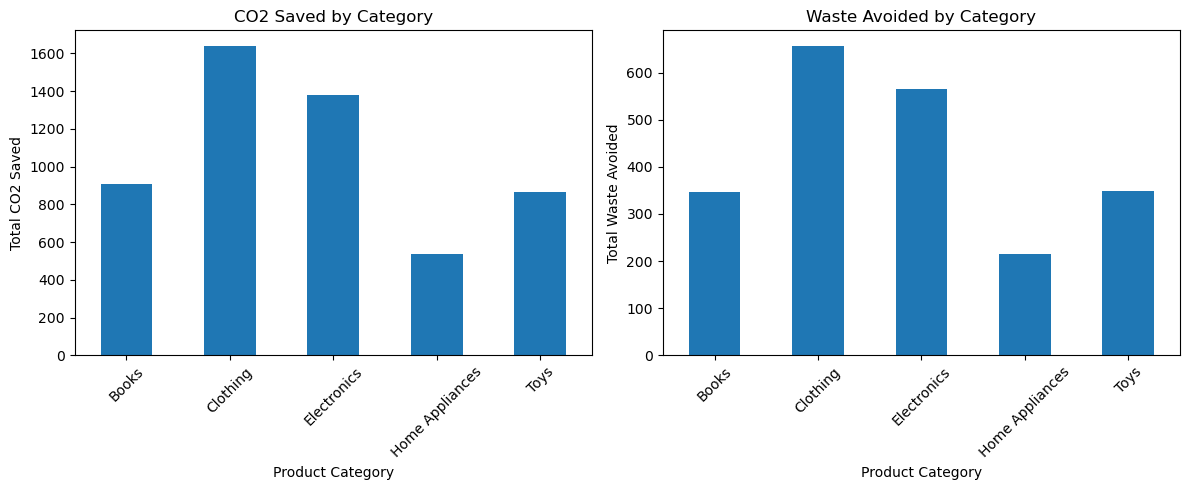

In [41]:

# Calculate sustainability impact by product category

sustainability = df1.groupby("Product_Category")[
    ["CO2_Saved", "Waste_Avoided"]
].sum()

print(sustainability.round(2))

# Create two separate charts
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sustainability["CO2_Saved"].plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("CO2 Saved by Category")
axes[0].set_xlabel("Product Category")
axes[0].set_ylabel("Total CO2 Saved")
axes[0].tick_params(axis="x", rotation=45)

sustainability["Waste_Avoided"].plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Waste Avoided by Category")
axes[1].set_xlabel("Product Category")
axes[1].set_ylabel("Total Waste Avoided")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()
